# ĐỀ TÀI 5: CÂY QUYẾT ĐỊNH VÀ CÁC PHƯƠNG PHÁP TỔ HỢP
## PHẦN A.4: CÀI ĐẶT THUẬT TOÁN XGBOOST TỪ ĐẦU & ĐỐI CHIẾU VỚI THƯ VIỆN GỐC (XGBOOST, LIGHTGBM)

**Mục tiêu của Notebook:**
1. **Kiểm chứng giải tích (Hand-check):** Xác minh công thức phân tách nhánh, trọng số lá tối ưu $w^*$ và độ lợi phân tách $\mathcal{L}_{\text{split}}$ theo đúng bài báo gốc của Chen & Guestrin (2016).
2. **Đối chiếu độ chính xác với thư viện:** So khớp kết quả của thuật toán tự cài đặt (`XGBRegressorCustom`) với thư viện `xgboost` và `lightgbm` chính thức trên dữ liệu tổng hợp (sai số cho phép $< 10^{-6}$).
3. **Thực nghiệm trên bài toán định giá căn hộ Hà Nội:** Huấn luyện trên tập dữ liệu `hanoi_apt_clean_5k.csv` (chia kiểm tra theo tuần cuối) để so sánh $\text{RMSE}_{\log}$ và $\text{MAPE}_{\text{giá}}$ giữa các mô hình.
4. **Trực quan hóa trực tiếp:** Hiển thị biểu đồ so sánh hiệu năng, biểu đồ tương quan Thực tế vs Dự đoán, và phân phối sai số phần dư.

---
### BƯỚC 0: Cấu hình môi trường và Kết nối Google Drive


In [1]:
# 1. Cài đặt các thư viện cần thiết
!pip install -q xgboost lightgbm matplotlib seaborn pandas numpy

import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb

# 2. Kết nối Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("✅ Đã mount Google Drive thành công!")
except Exception as e:
    print("ℹ️ Đang chạy ở môi trường local hoặc không có google.colab, bỏ qua mount Drive.")

# 3. Tự động định vị thư mục dự án trên Drive hoặc Local
POSSIBLE_PATHS = [
    "/content/drive/MyDrive/machinelearning/DeTai5_HanoiApt",
    "/content/drive/MyDrive/DeTai5_HanoiApt",
    "/content/drive/MyDrive/DeTai5_HanoiApt-20261123T134952Z-1-001/DeTai5_HanoiApt",
    "/content/drive/MyDrive/DeTai5_HanoiApt-20261123T134952Z-1-001",
    "/content/DeTai5_HanoiApt",
    ".",
    ".."
]

PROJECT_ROOT = None
for p in POSSIBLE_PATHS:
    check_path = Path(p).resolve()
    if (check_path / "src" / "xgb_custom.py").exists() or (check_path / "data").exists():
        PROJECT_ROOT = check_path
        break

if PROJECT_ROOT is not None:
    os.chdir(PROJECT_ROOT)
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))
    print(f"✅ Thư mục làm việc hiện tại: {os.getcwd()}")
else:
    print("⚠️ Lưu ý: Chưa tìm thấy thư mục gốc dự án. Bạn có thể thay đổi đường dẫn bằng os.chdir('đường_dẫn_của_bạn').")

Mounted at /content/drive
✅ Đã mount Google Drive thành công!
✅ Thư mục làm việc hiện tại: /content/drive/MyDrive/machinelearning/DeTai5_HanoiApt


---
### BƯỚC 1: Cài đặt thuật toán XGBoost Custom (Exact Greedy Newton Boosting)

Theo Chen & Guestrin (2016), mục tiêu tối ưu hàm mất mát bậc hai (Taylor Expansion):
$$\tilde{\mathcal{L}}^{(t)} \approx \sum_{i=1}^n \left[ g_i f_t(x_i) + \frac{1}{2} h_i f_t^2(x_i) \right] + \gamma T + \frac{1}{2}\lambda \sum_{j=1}^T w_j^2$$
Trong đó:
* $g_i = \hat{y}_i - y_i$ (Gradient của sai số bình phương).
* $h_i = 1$ (Hessian của sai số bình phương).
* Trọng số lá tối ưu: $w_j^* = -\frac{\sum_{i \in I_j} g_i}{\sum_{i \in I_j} h_i + \lambda}$.
* Độ lợi phân nhánh (Split Gain): $\mathcal{L}_{\text{split}} = \frac{1}{2} \left[ \frac{(\sum_L g_i)^2}{\sum_L h_i + \lambda} + \frac{(\sum_R g_i)^2}{\sum_R h_i + \lambda} - \frac{(\sum_I g_i)^2}{\sum_I h_i + \lambda} \right] - \gamma$.

In [2]:
from __future__ import annotations
from dataclasses import dataclass
from numbers import Integral

# Ưu tiên import từ file src/xgb_custom.py đã có trong repo
try:
    from src.xgb_custom import XGBRegressorCustom, Node
    print("✅ Đã nạp thành công XGBRegressorCustom từ src.xgb_custom!")
except Exception as e:
    print(f"ℹ️ Nạp fallback trực tiếp class XGBRegressorCustom (lý do: {e})")

    @dataclass
    class Node:
        weight: float
        feature: int = -1
        threshold: float = 0.0
        gain: float = 0.0
        left: Node | None = None
        right: Node | None = None

    class XGBRegressorCustom:
        def __init__(self, n_estimators=30, max_depth=3, learning_rate=0.1,
                     reg_lambda=1.0, gamma=0.0, min_child_weight=1.0):
            if (not isinstance(n_estimators, Integral) or n_estimators < 1
                    or not isinstance(max_depth, Integral) or max_depth < 0
                    or not 0 < learning_rate <= 1):
                raise ValueError("Invalid number of trees, depth or learning rate")
            regularization = np.array([reg_lambda, gamma, min_child_weight])
            if not np.isfinite(regularization).all() or (regularization < 0).any():
                raise ValueError("Regularization and minimum child weight must be nonnegative")
            self.n_estimators = n_estimators
            self.max_depth = max_depth
            self.learning_rate = learning_rate
            self.reg_lambda = reg_lambda
            self.gamma = gamma
            self.min_child_weight = min_child_weight

        def _grow(self, X, gradient, hessian, rows, depth):
            g, h = gradient[rows].sum(), hessian[rows].sum()
            penalty = self.reg_lambda
            node = Node(float(-g / (h + penalty)))
            if depth == self.max_depth or len(rows) < 2:
                return node
            parent_score = g**2 / (h + penalty)
            best_rows = None
            for feature in range(X.shape[1]):
                ordered = rows[np.argsort(X[rows, feature], kind="stable")]
                values = X[ordered, feature]
                gl = np.cumsum(gradient[ordered])[:-1]
                hl = np.cumsum(hessian[ordered])[:-1]
                gr, hr = g - gl, h - hl
                valid = ((values[:-1] < values[1:]) & (hl >= self.min_child_weight)
                         & (hr >= self.min_child_weight))
                gains = 0.5 * (gl**2 / (hl + penalty) + gr**2 / (hr + penalty)
                               - parent_score) - self.gamma
                gains[~valid] = -np.inf
                cut = int(np.argmax(gains))
                if gains[cut] > node.gain:
                    lower, upper = values[cut:cut + 2]
                    threshold = lower / 2 + upper / 2
                    node.feature = feature
                    node.threshold = float(threshold if threshold < upper else lower)
                    node.gain = float(gains[cut])
                    best_rows = ordered[:cut + 1], ordered[cut + 1:]
            if best_rows is not None:
                node.left = self._grow(X, gradient, hessian, best_rows[0], depth + 1)
                node.right = self._grow(X, gradient, hessian, best_rows[1], depth + 1)
            return node

        @staticmethod
        def _predict_tree(tree, X):
            result = np.empty(len(X))
            def visit(node, rows):
                if node.feature < 0:
                    result[rows] = node.weight
                    return
                left = X[rows, node.feature] <= node.threshold
                visit(node.left, rows[left])
                visit(node.right, rows[~left])
            visit(tree, np.arange(len(X)))
            return result

        def fit(self, X, y):
            X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
            if (X.ndim != 2 or not X.shape[0] or not X.shape[1] or y.shape != (len(X),)
                    or not np.isfinite(X).all() or not np.isfinite(y).all()):
                raise ValueError("Expected aligned, finite, nonempty numeric X and y")
            self.n_features_in_ = X.shape[1]
            self.base_score_ = float(y.mean())
            self.trees_ = []
            prediction = np.full(len(X), self.base_score_)
            hessian = np.ones(len(X))
            rows = np.arange(len(X))
            for _ in range(self.n_estimators):
                tree = self._grow(X, prediction - y, hessian, rows, 0)
                self.trees_.append(tree)
                prediction += self.learning_rate * self._predict_tree(tree, X)
            return self

        def predict(self, X):
            if not hasattr(self, "trees_"):
                raise ValueError("Fit the model before predicting")
            X = np.asarray(X, dtype=float)
            if X.ndim != 2 or X.shape[1] != self.n_features_in_ or not np.isfinite(X).all():
                raise ValueError("Expected finite X with the fitted feature count")
            prediction = np.full(len(X), self.base_score_)
            for tree in self.trees_:
                prediction += self.learning_rate * self._predict_tree(tree, X)
            return prediction
    print("✅ Khởi tạo class XGBRegressorCustom thành công!")

✅ Đã nạp thành công XGBRegressorCustom từ src.xgb_custom!


---
### BƯỚC 2: Kiểm chứng giải tích (Hand-check) & Đối chiếu với XGBoost / LightGBM

Dùng mẫu dữ liệu 1 chiều tối giản: $X = [0, 1, 2, 3]^T$, $y = [0, 0, 4, 4]^T$.
Với $n_{\text{estimators}}=1, \text{depth}=1, \eta=1, \lambda=1, \gamma=1$:
* Giá trị khởi tạo: $\text{base\_score} = \bar{y} = 2.0$.
* Gradient $g = \hat{y} - y = [2, 2, -2, -2]$, Hessian $h = [1, 1, 1, 1]$.
* Điểm cắt tối ưu: $x = 1.5$.
* Trọng số lá trái: $w_L = -\frac{2+2}{2+1} = -\frac{4}{3} \approx -1.3333$.
* Trọng số lá phải: $w_R = -\frac{-2-2}{2+1} = \frac{4}{3} \approx 1.3333$.
* Độ lợi Gain: $\mathcal{L}_{\text{split}} = \frac{1}{2}\left[\frac{4^2}{3} + \frac{(-4)^2}{3} - 0\right] - 1 = \frac{16}{3} - 1 = 4.3333$.
* Dự đoán tổng hợp: $\hat{y} = \text{base} + w = [2 - 4/3, 2 - 4/3, 2 + 4/3, 2 + 4/3] = [2/3, 2/3, 10/3, 10/3]$.

In [3]:
# 1. Khởi tạo dữ liệu mẫu
X_syn = np.arange(4).reshape(-1, 1)
y_syn = np.array([0, 0, 4, 4], dtype=float)

# 2. Huấn luyện mô hình Custom
model_custom = XGBRegressorCustom(n_estimators=1, max_depth=1, learning_rate=1.0,
                                 reg_lambda=1.0, gamma=1.0).fit(X_syn, y_syn)
root = model_custom.trees_[0]
pred_custom_syn = model_custom.predict(X_syn)
expected_syn = np.array([2/3, 2/3, 10/3, 10/3])

# Kiểm chứng chính xác
np.testing.assert_allclose(
    [root.threshold, root.left.weight, root.right.weight, root.gain],
    [1.5, -4/3, 4/3, 16/3 - 1],
    rtol=1e-6
)
np.testing.assert_allclose(pred_custom_syn, expected_syn, rtol=1e-6)

print("="*60)
print("KẾT QUẢ ĐỐI CHIẾU CÔNG THỨC GIẢI TÍCH (HAND-CHECK):")
print("="*60)
print(f"* Ngưỡng phân tách (Threshold) : {root.threshold:.2f} (Lý thuyết: 1.50)")
print(f"* Trọng số lá trái (w_Left)     : {root.left.weight:.4f} (Lý thuyết: -4/3 = -1.3333)")
print(f"* Trọng số lá phải (w_Right)    : {root.right.weight:.4f} (Lý thuyết: 4/3 = 1.3333)")
print(f"* Độ lợi Gain                  : {root.gain:.4f} (Lý thuyết: 16/3 - 1 = 4.3333)")
print(f"* Dự đoán Custom trên X_syn    : {np.round(pred_custom_syn, 4)}")
print(f"* Kỳ vọng lý thuyết             : {np.round(expected_syn, 4)}")

# 3. Đối chiếu với XGBoost và LightGBM chính thức
# (Lưu ý: Thư viện tính split gain không nhân hệ số 1/2, do đó gamma tương ứng là 2.0)
dsmall = xgb.DMatrix(X_syn, label=y_syn, nthread=1)
model_xgb_syn = xgb.train({"objective": "reg:squarederror", "tree_method": "exact",
                          "base_score": 2.0, "max_depth": 1, "eta": 1.0,
                          "lambda": 1.0, "gamma": 2.0, "nthread": 1}, dsmall, 1)

model_lgb_syn = lgb.train({"objective": "regression", "max_depth": 1, "num_leaves": 2,
                          "learning_rate": 1.0, "lambda_l2": 1.0, "min_gain_to_split": 2.0,
                          "min_data_in_leaf": 1, "min_data_in_bin": 1,
                          "num_threads": 1, "verbosity": -1}, lgb.Dataset(X_syn, label=y_syn), 1)

pred_xgb_syn = model_xgb_syn.predict(dsmall)
pred_lgb_syn = model_lgb_syn.predict(X_syn)

max_err_xgb = np.max(np.abs(pred_xgb_syn - expected_syn))
max_err_lgb = np.max(np.abs(pred_lgb_syn - expected_syn))

print("-"*60)
print("ĐỘ LỆCH DỰ ĐOÁN SO VỚI CÁC THƯ VIỆN GỐC:")
print(f"* Sai lệch tuyệt đối max so với XGBoost  : {max_err_xgb:.2e}")
print(f"* Sai lệch tuyệt đối max so với LightGBM : {max_err_lgb:.2e}")
print("="*60)

KẾT QUẢ ĐỐI CHIẾU CÔNG THỨC GIẢI TÍCH (HAND-CHECK):
* Ngưỡng phân tách (Threshold) : 1.50 (Lý thuyết: 1.50)
* Trọng số lá trái (w_Left)     : -1.3333 (Lý thuyết: -4/3 = -1.3333)
* Trọng số lá phải (w_Right)    : 1.3333 (Lý thuyết: 4/3 = 1.3333)
* Độ lợi Gain                  : 4.3333 (Lý thuyết: 16/3 - 1 = 4.3333)
* Dự đoán Custom trên X_syn    : [0.6667 0.6667 3.3333 3.3333]
* Kỳ vọng lý thuyết             : [0.6667 0.6667 3.3333 3.3333]
------------------------------------------------------------
ĐỘ LỆCH DỰ ĐOÁN SO VỚI CÁC THƯ VIỆN GỐC:
* Sai lệch tuyệt đối max so với XGBoost  : 1.59e-07
* Sai lệch tuyệt đối max so với LightGBM : 4.44e-16


---
### BƯỚC 3: Đánh giá thực tế trên bài toán Định giá căn hộ Hà Nội

* **Tập dữ liệu:** `hanoi_apt_clean_5k.csv`
* **Đặc trưng ($X$):** `area_m2`, `bedrooms`, `bathrooms`, `has_red_book`, `interior_level`.
* **Biến mục tiêu ($y$):** $\log(\text{price\_per\_m2})$.
* **Chiến lược phân chia:** Tách tuần cuối cùng thu thập làm tập kiểm tra độc lập (Temporal Test Set).
* **Siêu tham số:** 30 vòng lặp, độ sâu 3, learning_rate = 0.1, L2 regularization $\lambda = 1.0$.

In [4]:
import csv

FEATURES = ("area_m2", "bedrooms", "bathrooms", "has_red_book", "interior_level")

# 1. Tìm tệp dữ liệu
CANDIDATES = [
    Path("data/processed/hanoi_apt_clean_5k.csv"),
    Path("hanoi_apt_clean_5k.csv"),
    Path("data/hanoi_apt_final.csv"),
    Path("hanoi_apt_final.csv")
]
data_path = None
for c in CANDIDATES:
    if c.exists():
        data_path = c
        break

if data_path is None:
    raise FileNotFoundError("Không tìm thấy file dữ liệu hanoi_apt_clean_5k.csv hoặc hanoi_apt_final.csv!")
print(f"✅ Sử dụng tệp dữ liệu: {data_path}")

# 2. Đọc và chuẩn bị dữ liệu (Temporal Split: 7 ngày cuối làm Test)
with open(data_path, encoding="utf-8-sig", newline="") as f:
    rows = list(csv.DictReader(f))

dates = np.array([r["collected_at"][:10] for r in rows], dtype="datetime64[D]")
last_date = dates.max()
test_mask = dates >= (last_date - np.timedelta64(6, "D"))

X = np.array([[float(r[name] or "nan") for name in FEATURES] for r in rows])
y = np.array([float(r["log_price_m2"]) for r in rows])

# Điền median từ tập train
median_vals = np.nanmedian(X[~test_mask], axis=0)
median_vals = np.where(np.isfinite(median_vals), median_vals, 0)
X = np.where(np.isnan(X), median_vals, X)

train_X, train_y = X[~test_mask], y[~test_mask]
test_X, test_y = X[test_mask], y[test_mask]
start_test_date = str(last_date - np.timedelta64(6, "D"))
end_test_date = str(last_date)

print(f"* Tổng số mẫu                  : {len(X):,} dòng")
print(f"* Tập huấn luyện (Train)       : {len(train_X):,} dòng")
print(f"* Tập kiểm tra tuần cuối (Test): {len(test_X):,} dòng (từ {start_test_date} đến {end_test_date})")

# 3. Huấn luyện 4 mô hình
rounds, depth, rate, penalty = 30, 3, 0.1, 1.0

print("\n--- Tiến hành huấn luyện các mô hình ---")
# a. Baseline (Mean log-price)
pred_mean = np.full(len(test_y), train_y.mean())

# b. Custom XGBoost
print("1. Huấn luyện Custom XGBoost (NumPy)... ", end="")
model_custom = XGBRegressorCustom(n_estimators=rounds, max_depth=depth,
                                  learning_rate=rate, reg_lambda=penalty).fit(train_X, train_y)
pred_custom = model_custom.predict(test_X)
print("Xong!")

# c. XGBoost chính thức
print("2. Huấn luyện XGBoost (Thư viện chính thức)... ", end="")
dtrain = xgb.DMatrix(train_X, label=train_y, nthread=4)
dtest = xgb.DMatrix(test_X, nthread=4)
model_xgb = xgb.train({"objective": "reg:squarederror", "tree_method": "exact",
                       "base_score": float(train_y.mean()), "max_depth": depth,
                       "eta": rate, "lambda": penalty, "nthread": 4}, dtrain, rounds)
pred_xgb = model_xgb.predict(dtest)
print("Xong!")

# d. LightGBM chính thức
print("3. Huấn luyện LightGBM (Thư viện chính thức)... ", end="")
model_lgb = lgb.train({"objective": "regression", "max_depth": depth,
                       "num_leaves": 2**depth, "learning_rate": rate,
                       "lambda_l2": penalty, "min_data_in_leaf": 1, "min_data_in_bin": 1,
                       "num_threads": 4, "verbosity": -1},
                      lgb.Dataset(train_X, label=train_y), rounds)
pred_lgb = model_lgb.predict(test_X)
print("Xong!")

# 4. Hàm tính thước đo RMSE thang log và MAPE giá thực tế
def calc_metrics(pred, true):
    error = pred - true
    rmse = float(np.sqrt(np.mean(error**2)))
    mape = float(100 * np.mean(np.abs(np.expm1(error))))
    return rmse, mape

results = {
    "Baseline (Mean)": calc_metrics(pred_mean, test_y),
    "Custom XGBoost": calc_metrics(pred_custom, test_y),
    "XGBoost (Library)": calc_metrics(pred_xgb, test_y),
    "LightGBM (Library)": calc_metrics(pred_lgb, test_y),
}

df_results = pd.DataFrame(results, index=["RMSE log", "MAPE giá (%)"]).T
display(df_results.style.format({"RMSE log": "{:.5f}", "MAPE giá (%)": "{:.2f}%"}))

✅ Sử dụng tệp dữ liệu: data/processed/hanoi_apt_clean_5k.csv
* Tổng số mẫu                  : 189,293 dòng
* Tập huấn luyện (Train)       : 184,532 dòng
* Tập kiểm tra tuần cuối (Test): 4,761 dòng (từ 2026-03-24 đến 2026-03-30)

--- Tiến hành huấn luyện các mô hình ---
1. Huấn luyện Custom XGBoost (NumPy)... Xong!
2. Huấn luyện XGBoost (Thư viện chính thức)... Xong!
3. Huấn luyện LightGBM (Thư viện chính thức)... Xong!


,RMSE log,MAPE giá (%)
Baseline (Mean),0.30694,21.77%
Custom XGBoost,0.29209,20.99%
XGBoost (Library),0.29209,20.99%
LightGBM (Library),0.29232,21.00%


---
### BƯỚC 4: Trực quan hóa kết quả đồ họa (Visualizations)

<>:45: SyntaxWarning: invalid escape sequence '\h'
<>:45: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_2299/3231855624.py:45: SyntaxWarning: invalid escape sequence '\h'
  axes[0].plot(lims, lims, "r--", linewidth=2, label="Đường lý tưởng $y = \hat{y}$")


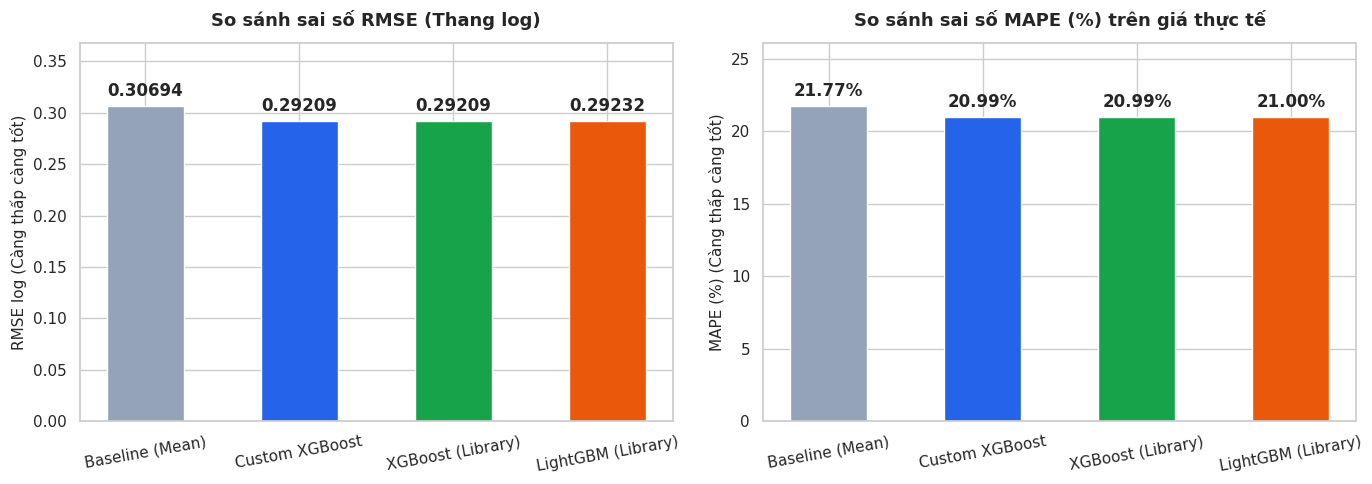

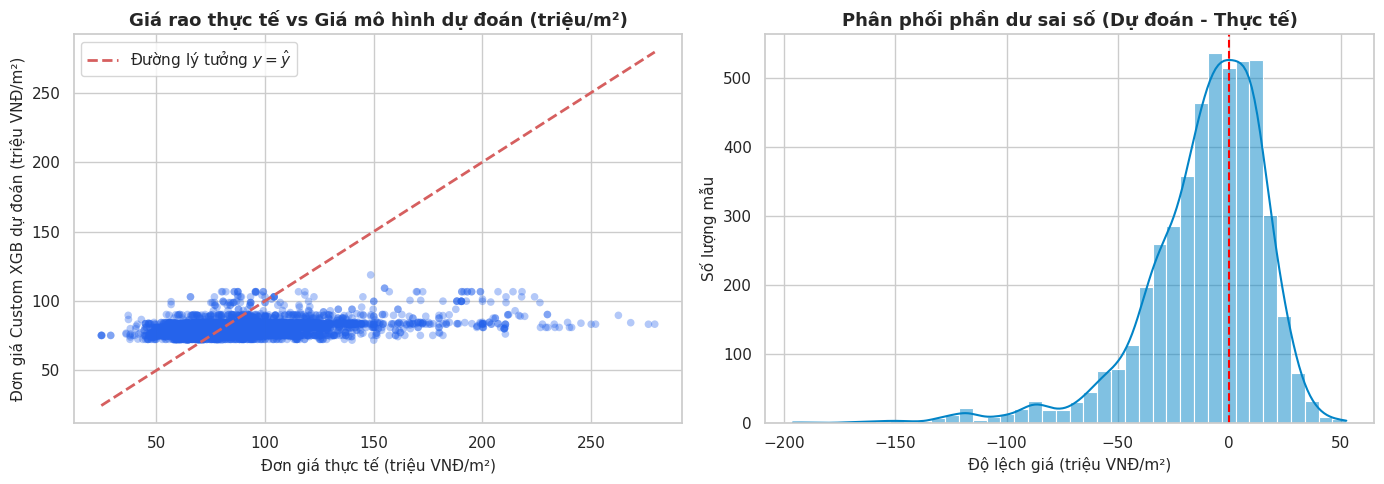

In [5]:
# Thiết lập giao diện biểu đồ
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = list(results.keys())
rmse_scores = [results[m][0] for m in models]
mape_scores = [results[m][1] for m in models]
colors = ["#94a3b8", "#2563eb", "#16a34a", "#ea580c"]

# 1. Biểu đồ cột RMSE (thang log)
bars1 = axes[0].bar(models, rmse_scores, color=colors, width=0.5)
axes[0].set_title("So sánh sai số RMSE (Thang log)", fontsize=13, fontweight="bold", pad=12)
axes[0].set_ylabel("RMSE log (Càng thấp càng tốt)", fontsize=11)
axes[0].set_ylim(0, max(rmse_scores) * 1.2)
for bar in bars1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 0.006, f"{yval:.5f}", ha="center", va="bottom", fontweight="bold")
axes[0].tick_params(axis="x", rotation=10)

# 2. Biểu đồ cột MAPE (%)
bars2 = axes[1].bar(models, mape_scores, color=colors, width=0.5)
axes[1].set_title("So sánh sai số MAPE (%) trên giá thực tế", fontsize=13, fontweight="bold", pad=12)
axes[1].set_ylabel("MAPE (%) (Càng thấp càng tốt)", fontsize=11)
axes[1].set_ylim(0, max(mape_scores) * 1.2)
for bar in bars2:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 0.4, f"{yval:.2f}%", ha="center", va="bottom", fontweight="bold")
axes[1].tick_params(axis="x", rotation=10)

plt.tight_layout()
plt.show()

# Biểu đồ phân tích dự báo thực tế vs dự đoán (triệu VNĐ/m2)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

actual_price = np.exp(test_y)
pred_price = np.exp(pred_custom)
res_price = pred_price - actual_price

# 3. Scatter Plot Actual vs Predicted
axes[0].scatter(actual_price, pred_price, alpha=0.35, color="#2563eb", s=30, edgecolors="none")
lims = [min(actual_price.min(), pred_price.min()), max(actual_price.max(), pred_price.max())]
axes[0].plot(lims, lims, "r--", linewidth=2, label="Đường lý tưởng $y = \hat{y}$")
axes[0].set_title("Giá rao thực tế vs Giá mô hình dự đoán (triệu/m²)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Đơn giá thực tế (triệu VNĐ/m²)", fontsize=11)
axes[0].set_ylabel("Đơn giá Custom XGB dự đoán (triệu VNĐ/m²)", fontsize=11)
axes[0].legend()

# 4. Residual Distribution
sns.histplot(res_price, kde=True, ax=axes[1], color="#0284c7", bins=40)
axes[1].axvline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_title("Phân phối phần dư sai số (Dự đoán - Thực tế)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Độ lệch giá (triệu VNĐ/m²)", fontsize=11)
axes[1].set_ylabel("Số lượng mẫu", fontsize=11)

plt.tight_layout()
plt.show()

---
### BƯỚC 5: Xuất kết quả Artifacts (`artifacts/tables/a4_xgb_comparison.json`)
*Lưu lại kết quả dưới dạng JSON để báo cáo LaTeX hoặc Word có thể đồng bộ số liệu tự động.*

In [ ]:
import json

out_payload = {
    "numpy_version": np.__version__,
    "formula_check": {
        "threshold": float(root.threshold),
        "gain": float(root.gain),
        "left_weight": float(root.left.weight),
        "right_weight": float(root.right.weight)
    },
    "library_versions": {
        "xgboost": xgb.__version__,
        "lightgbm": lgb.__version__
    },
    "synthetic_max_abs_error": {
        "XGBoost": float(max_err_xgb),
        "LightGBM": float(max_err_lgb)
    },
    "dataset": str(data_path).replace("\\", "/"),
    "train_rows": int(len(train_X)),
    "test_rows": int(len(test_X)),
    "test_dates": [start_test_date, end_test_date],
    "features": list(FEATURES),
    "parameters": {
        "rounds": rounds,
        "max_depth": depth,
        "learning_rate": rate,
        "lambda_l2": penalty
    },
    "test_metrics": {
        m: {
            "rmse_log": results[m][0],
            "mape_price_pct": results[m][1]
        }
        for m in results
    }
}

out_file = Path("artifacts/tables/a4_xgb_comparison.json")
out_file.parent.mkdir(parents=True, exist_ok=True)
out_file.write_text(json.dumps(out_payload, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

print(f" Đã xuất kết quả thành công vào: {out_file.resolve()}")
print(json.dumps(out_payload["test_metrics"], indent=2))

✅ Đã xuất kết quả thành công vào: /content/drive/MyDrive/machinelearning/DeTai5_HanoiApt/artifacts/tables/a4_xgb_comparison.json
{
  "Baseline (Mean)": {
    "rmse_log": 0.3069425003860385,
    "mape_price_pct": 21.771516421201543
  },
  "Custom XGBoost": {
    "rmse_log": 0.29208777825748433,
    "mape_price_pct": 20.987960462581885
  },
  "XGBoost (Library)": {
    "rmse_log": 0.29208774065847515,
    "mape_price_pct": 20.987959662275006
  },
  "LightGBM (Library)": {
    "rmse_log": 0.292318608648211,
    "mape_price_pct": 20.99846062032964
  }
}
